# Customer Segmentation Using Affinity Propagation

## Project Overview

This notebook uses **Affinity Propagation** to group customers based on **Annual Income (k$)** and **Spending Score (1-100)**. It walks through data checks, feature scaling, preference tuning, cluster assignment, visualization, and profile interpretation. The algorithm identifies representative customers, called *exemplars*, and uses the similarity between customers to determine the groups.

# Business Problem

A company wants to understand customer income and spending patterns so it can develop more relevant marketing strategies. Affinity Propagation groups customers based on similarity in Annual Income and Spending Score. The resulting groups can be explored to understand differences in customer behavior.

The current model uses **Annual Income (k$)** and **Spending Score (1-100)**. Gender and Age are not used as clustering features in this version.

## Objective

Develop an Affinity Propagation clustering model that groups customers using:
- Annual Income (k$)
- Spending Score (1-100)

The goal is to discover customer segments and describe their characteristics. The model does not predict whether a customer will purchase a product. The number of clusters is not specified directly; it is influenced by the `preference` parameter and the similarities between customers.

## Workflow

1. Import the required libraries.
2. Load and inspect the dataset.
3. Validate the data.
4. Select the features used for clustering.
5. Scale the features.
6. Calculate pairwise similarities and test candidate preference values.
7. Compare candidate solutions using cluster count and silhouette score.
8. Fit the selected Affinity Propagation model and assign cluster labels.
9. Identify the exemplar customer for each cluster.
10. Visualize, profile, and interpret the clusters.
11. Export the clustered dataset.

### Import the required libraries.

In [1]:
# Bring in the libraries used in this notebook
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import AffinityPropagation
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import euclidean_distances

import warnings
warnings.filterwarnings('ignore')

### Load and inspect the dataset.

In [2]:
# Load the customer data from the CSV file
dataset = pd.read_csv("../data/Mall_Customers.csv")

In [3]:
# Take a quick look at the first five rows
dataset.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Data validation

In [4]:
# Check the data for missing values, duplicates, and data types
print("Dataset shape:", dataset.shape)

print("\nMissing values:")
print(dataset.isnull().sum())

print("\nDuplicate rows:", dataset.duplicated().sum())

print("\nData types:")
print(dataset.dtypes)

Dataset shape: (200, 5)

Missing values:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0

Data types:
CustomerID                 int64
Genre                     object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


In [5]:
# Take a quick look at the first five rows
dataset.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [6]:
# CustomerID only identifies each customer, so it will not help group similar customers.
# Keep the remaining customer details for the analysis later on.
dataset = dataset.drop(columns=["CustomerID"])

In [7]:
# Take a quick look at the first five rows
dataset.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


### Feature selection

In [8]:
# Use annual income and spending score to group customers
features = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = dataset[features].copy()

In [9]:
# Check the two features that will be used for clustering
X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


## Feature scaling

In [10]:
# Put both features on a comparable scale before clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Tune Affinity Propagation

Affinity Propagation does not require a predefined number of clusters, so the Elbow Method and WCSS are not used. Instead, test different `preference` values. The preference is compared with pairwise similarity values and influences how many exemplars—and thus clusters—are selected. This notebook generates candidate preferences from the observed similarity distribution, then compares the resulting cluster counts and silhouette scores.

In [11]:
# Measure how different each pair of customers is and prepare possible preference values.
# For Euclidean affinity, scikit-learn uses negative squared distances as similarities.
similarity_matrix = -euclidean_distances(X_scaled, squared=True)
off_diagonal_similarities = similarity_matrix[~np.eye(similarity_matrix.shape[0], dtype=bool)]

preference_quantiles = [0.10, 0.25, 0.50, 0.75, 0.90]
candidate_preferences = np.unique(
    np.quantile(off_diagonal_similarities, preference_quantiles).round(6)
)

pd.DataFrame({
    'Quantile': preference_quantiles[:len(candidate_preferences)],
    'Candidate_Preference': candidate_preferences
})

,Quantile,Candidate_Preference
0,0.10,-9.582755
1,0.25,-5.504362
2,0.50,-3.004489
3,0.75,-1.007021
4,0.90,-0.230542


In [12]:
# Try different preference values and see how the clusters change
preference_results = []

for preference in candidate_preferences:
    candidate_model = AffinityPropagation(
        affinity='euclidean',
        preference=float(preference),
        damping=0.7,
        max_iter=500,
        convergence_iter=15,
        random_state=42
    )
    candidate_labels = candidate_model.fit_predict(X_scaled)
    n_clusters = len(candidate_model.cluster_centers_indices_) if candidate_model.cluster_centers_indices_ is not None else 0
    unique_labels = np.unique(candidate_labels)
    score = (
        silhouette_score(X_scaled, candidate_labels)
        if 1 < len(unique_labels) < len(candidate_labels)
        else np.nan
    )
    preference_results.append({
        'Preference': float(preference),
        'Number_of_Clusters': n_clusters,
        'Silhouette_Score': score,
        'Converged': candidate_model.n_iter_ < candidate_model.max_iter
    })

preference_df = pd.DataFrame(preference_results)
preference_df.round(3)

,Preference,Number_of_Clusters,Silhouette_Score,Converged
0,-9.583,7,0.452,True
1,-5.504,8,0.446,True
2,-3.004,11,0.442,True
3,-1.007,19,0.419,True
4,-0.231,40,0.431,True


In [13]:
# Compare the results from the different preference values.
# Choose a solution with useful, understandable customer groups—not just the highest score.
preference_df.sort_values('Silhouette_Score', ascending=False, na_position='last')

,Preference,Number_of_Clusters,Silhouette_Score,Converged
0,-9.582755,7,0.452135,True
1,-5.504362,8,0.445931,True
2,-3.004489,11,0.442196,True
4,-0.230542,40,0.430583,True
3,-1.007021,19,0.418507,True


## Select and Fit the Final Affinity Propagation Model

The candidate comparison evaluates each preference value using the number of clusters, silhouette score, and convergence status. For this notebook, the final preference is selected from the candidate with the highest valid silhouette score. This gives a clear, repeatable selection rule instead of choosing the median preference without a reason. The final cluster count is determined by Affinity Propagation; it is not set in advance.

**Note:** The silhouette score is only one measure of cluster separation. Review the resulting customer profiles as well, because a useful segmentation should also be understandable and relevant to the business question.

In [14]:
# Use the candidate with the highest valid silhouette score.
# The comparison table above shows the score and cluster count for each candidate.
best_candidate = preference_df.dropna(subset=['Silhouette_Score']).sort_values(
    'Silhouette_Score', ascending=False
).iloc[0]
selected_preference = float(best_candidate['Preference'])

ap = AffinityPropagation(
    affinity='euclidean',
    preference=selected_preference,
    damping=0.7,
    max_iter=500,
    convergence_iter=15,
    random_state=42
)
cluster_labels = ap.fit_predict(X_scaled)

n_clusters = len(ap.cluster_centers_indices_) if ap.cluster_centers_indices_ is not None else len(np.unique(cluster_labels))
print('Selected preference:', round(selected_preference, 4))
print('Number of clusters:', n_clusters)
print('Iterations used:', ap.n_iter_)
if ap.n_iter_ >= ap.max_iter:
    print('Warning: the model reached max_iter. Consider increasing max_iter or adjusting damping/preference.')

Selected preference: -9.5828
Number of clusters: 7
Iterations used: 28


In [15]:
# Check which cluster each customer belongs to
cluster_labels

array([0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 2, 1, 2, 2,
       0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 3, 2, 2, 2, 2, 2,
       2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 3, 4, 3, 4, 5, 4, 5, 4,
       3, 4, 5, 4, 5, 4, 5, 4, 5, 4, 3, 4, 5, 4, 3, 4, 5, 4, 5, 4, 5, 4,
       5, 4, 5, 4, 5, 4, 3, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4, 5, 4,
       5, 4, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6, 5, 6,
       5, 6])

In [16]:
# Make a copy so the original dataset stays unchanged
clustered_customers = dataset.copy()

In [17]:
# Review the customer records before adding their cluster labels
clustered_customers.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


## Cluster Assignment

In [18]:
# Save each customer’s cluster assignment alongside their details
clustered_customers["Cluster_group"] = cluster_labels

clustered_customers.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster_group
0,Male,19,15,39,0
1,Male,21,15,81,1
2,Female,20,16,6,0
3,Female,23,16,77,1
4,Female,31,17,40,0


In [19]:
# Save the customer groups to a CSV file, creating the output folder if needed
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "affinity_propagation_cluster.csv"
clustered_customers.to_csv(output_file, index=False)

print(f"Clustered data saved to: {output_file.resolve()}")

Clustered data saved to: D:\Hope\AI Course Tamil\ML\Clustering\outputs\affinity_propagation_cluster.csv


## Cluster Exemplars

Affinity Propagation selects an **exemplar**—an actual customer record that best represents each cluster. The following code retrieves these representative customers and displays their income and spending score in the original units.

In [20]:
# Find the representative customers (exemplars) and show their values in the original units
if ap.cluster_centers_indices_ is None:
    print('No exemplars were identified. Review convergence and preference settings.')
    exemplars_df = pd.DataFrame(columns=features + ['Cluster_group'])
else:
    exemplar_indices = ap.cluster_centers_indices_
    exemplars_original = scaler.inverse_transform(X_scaled[exemplar_indices])
    exemplars_df = pd.DataFrame(exemplars_original, columns=features)
    exemplars_df['Cluster_group'] = cluster_labels[exemplar_indices]
    exemplars_df = exemplars_df.sort_values('Cluster_group').reset_index(drop=True)

exemplars_df.round(2)

,Annual Income (k$),Spending Score (1-100),Cluster_group
0,28.0,14.0,0
1,28.0,82.0,1
2,48.0,51.0,2
3,64.0,46.0,3
4,79.0,83.0,4
5,88.0,15.0,5
6,103.0,85.0,6


In [21]:
# Count how many customers were assigned to each cluster
clustered_customers["Cluster_group"].value_counts().sort_index()

Cluster_group
0    21
1    21
2    45
3    42
4    28
5    32
6    11
Name: count, dtype: int64

## Cluster Visualization

Plot Annual Income against Spending Score, with color indicating the assigned cluster.

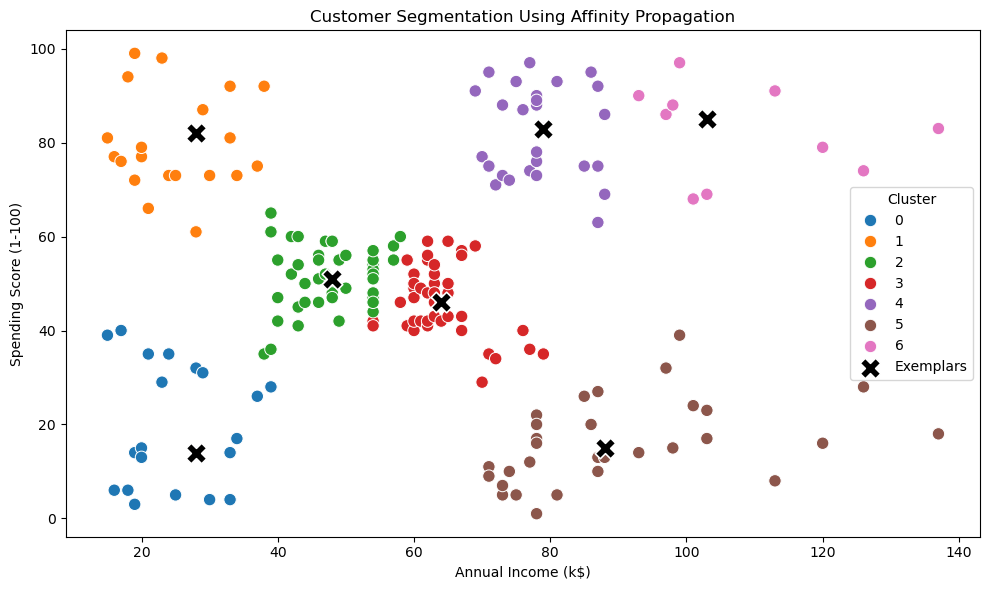

In [22]:
# Plot the customer groups and mark each group’s representative customer
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clustered_customers,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster_group',
    palette='tab10',
    s=80
)

if not exemplars_df.empty:
    sns.scatterplot(
        data=exemplars_df,
        x='Annual Income (k$)',
        y='Spending Score (1-100)',
        color='black',
        marker='X',
        s=220,
        label='Exemplars'
    )

plt.title('Customer Segmentation Using Affinity Propagation')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

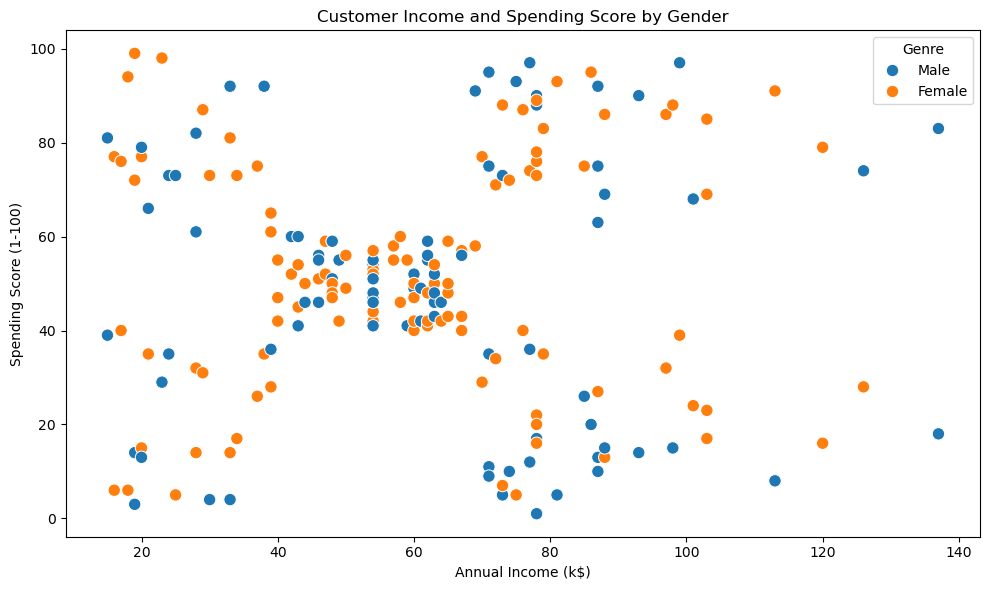

In [23]:
# Optional: compare income and spending patterns by gender.
# Gender is shown here for exploration only; it is not used to form the clusters.
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clustered_customers,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Genre',
    s=80
)

plt.title('Customer Income and Spending Score by Gender')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.tight_layout()
plt.show()

## Cluster profiling

The table below reports the number and percentage of customers in each cluster, along with the average income and spending score. Use these values to describe the segments; cluster numbers are arbitrary labels.

In [24]:
# Summarize the customer count, average income, and average spending for each cluster
cluster_profile = clustered_customers.groupby("Cluster_group").agg(
    Customer_Count=("Cluster_group", "size"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"] / len(clustered_customers) * 100
).round(2)

cluster_profile

,Customer_Count,Average_Income,Average_Spending_Score,Customer_Percentage
Cluster_group,,,,
0,21,25.14,19.52,10.5
1,21,25.10,80.05,10.5
2,45,47.44,51.24,22.5
3,42,63.95,46.21,21.0
4,28,78.04,81.89,14.0
5,32,89.41,15.59,16.0
6,11,108.18,82.73,5.5


In [25]:
# Add plain-language descriptions and possible next steps for each cluster.
# These labels are based on the dataset's median income and spending score.
income_median = clustered_customers["Annual Income (k$)"].median()
spending_median = clustered_customers["Spending Score (1-100)"].median()

def describe_level(value, median, metric_name):
    if value < median * 0.90:
        return "Below median"
    if value > median * 1.10:
        return "Above median"
    return "Around median"

def suggest_action(row):
    income_level = row["Income_Level"]
    spending_level = row["Spending_Level"]

    if spending_level == "Above median" and income_level == "Above median":
        return "Consider loyalty benefits or premium offers; test response before scaling."
    if spending_level == "Above median":
        return "Test relevant bundles or loyalty offers for customers already showing strong spending."
    if income_level == "Above median" and spending_level == "Below median":
        return "Test targeted engagement and learn what may be limiting spending."
    if spending_level == "Below median":
        return "Test low-friction offers or product recommendations; avoid assuming income explains behavior."
    return "Use general engagement campaigns and monitor response."

cluster_interpretation = cluster_profile.copy()
cluster_interpretation["Income_Level"] = cluster_interpretation["Average_Income"].apply(
    lambda value: describe_level(value, income_median, "income")
)
cluster_interpretation["Spending_Level"] = cluster_interpretation["Average_Spending_Score"].apply(
    lambda value: describe_level(value, spending_median, "spending")
)
cluster_interpretation["Suggested_Action"] = cluster_interpretation.apply(suggest_action, axis=1)

cluster_interpretation.reset_index().round(2)

,Cluster_group,Customer_Count,Average_Income,Average_Spending_Score,Customer_Percentage,Income_Level,Spending_Level,Suggested_Action
0,0,21,25.14,19.52,10.5,Below median,Below median,Test low-friction offers or product recommenda...
1,1,21,25.10,80.05,10.5,Below median,Above median,Test relevant bundles or loyalty offers for cu...
2,2,45,47.44,51.24,22.5,Below median,Around median,Use general engagement campaigns and monitor r...
3,3,42,63.95,46.21,21.0,Around median,Around median,Use general engagement campaigns and monitor r...
4,4,28,78.04,81.89,14.0,Above median,Above median,Consider loyalty benefits or premium offers; t...
5,5,32,89.41,15.59,16.0,Above median,Below median,Test targeted engagement and learn what may be...
6,6,11,108.18,82.73,5.5,Above median,Above median,Consider loyalty benefits or premium offers; t...


## Interpreting the Cluster Profiles

Use the **cluster profile table** and the **plain-language interpretation table** above to describe the groups produced by the final Affinity Propagation model. The interpretation table is generated from the model's actual cluster averages, so it stays aligned if the selected preference changes the number of clusters.

- **Income level** and **spending level** are compared with the dataset medians; they are descriptive labels, not customer rankings.
- **Suggested actions** are starting hypotheses for marketing tests, not proven explanations of customer behavior.
- Cluster numbers are arbitrary labels. A higher cluster number does not mean a better or more valuable customer group.
- The profile averages describe each cluster as a whole; individual customers may differ from those averages.

## Conclusion

Affinity Propagation was applied to group customers using annual income and spending score. The candidate preference values were compared using silhouette score and convergence, and the final model uses the candidate with the highest valid silhouette score. Cluster profiles then summarize the size, average income, and average spending score of each group.

The results can help a business form initial hypotheses for customer engagement—for example, testing loyalty offers for groups with higher spending scores or targeted engagement for groups with higher income but lower spending scores. These actions should be tested against actual campaign results before making broader decisions.